# pipekit-train — the Keras backend

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/pipekit/blob/main/docs/notebooks/pipekit_train_keras.ipynb)

`backend="keras"` trains a model with Keras 3's own `compile` and `fit`, on the JAX backend. This notebook first trains a small Keras model with plain Keras, then trains the same model through `TrainingLoop`, which adds a dataset hash, a metric log, checkpoints that resume and an operator for the registry. It then trains one Equinox emulator under both the Keras and the Equinox backends and compares them. The design is `packages/pipekit-train/docs/design/keras_adapter.md`.

In [1]:
import os
import subprocess
import sys


# Keras reads its backend once, at its first import; pipekit-train runs on JAX.
os.environ.setdefault("KERAS_BACKEND", "jax")

try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "pipekit-train[keras,equinox] @ git+https://github.com/jejjohnson/pipekit@main#subdirectory=packages/pipekit-train",
            "pipekit @ git+https://github.com/jejjohnson/pipekit@main#subdirectory=packages/pipekit",
        ],
        check=True,
    )

In [2]:
import json
import tempfile
from pathlib import Path

import equinox as eqx
import jax
import keras
import matplotlib.pyplot as plt
import numpy as np
from pipekit_jax import JaxModelOp
from pipekit_train import (
    MSE,
    EarlyStopping,
    IterableDataset,
    JSONLWriter,
    TrainingLoop,
)
from pipekit_train.backends.keras import EquinoxLayer, KerasModelOp


print("keras", keras.__version__, "on", keras.config.backend())

keras 3.14.1 on jax


## 1. Toy regression data

Inputs x are drawn from a standard normal, and the targets are y = x w + b + ε with fixed weights w, offset b = 0.3 and noise ε of standard deviation 0.1. The first 512 rows train and the last 128 validate.

In [3]:
rng = np.random.default_rng(0)
weights = np.array([[1.0], [-2.0], [0.5]], dtype="float32")
inputs = rng.normal(size=(640, 3)).astype("float32")
noise = 0.1 * rng.normal(size=(640, 1)).astype("float32")
targets = inputs @ weights + 0.3 + noise
x_train, y_train = inputs[:512], targets[:512]
x_val, y_val = inputs[512:], targets[512:]
print(x_train.shape, y_train.shape, x_val.shape, y_val.shape)

(512, 3) (512, 1) (128, 3) (128, 1)


## 2. A Keras model, with plain Keras

`compile`, `fit` and `predict`: 125 epochs of 16 steps at most, with Keras's own early stopping on the validation loss.

In [4]:
def build_model(seed: int = 0) -> keras.Model:
    keras.utils.set_random_seed(seed)
    return keras.Sequential(
        [
            keras.Input((3,)),
            keras.layers.Dense(64, activation="gelu"),
            keras.layers.Dense(1),
        ]
    )


model = build_model()
model.compile(optimizer=keras.optimizers.AdamW(learning_rate=1e-3), loss="mse")
history = model.fit(
    x_train,
    y_train,
    batch_size=32,
    epochs=125,
    validation_data=(x_val, y_val),
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=3)],
    verbose=0,
)
predictions = model.predict(x_val, verbose=0)
epochs = len(history.history["loss"])
print(f"{epochs} epochs; validation MSE {history.history['val_loss'][-1]:.4f}")

59 epochs; validation MSE 0.0109


## 3. The same model through `TrainingLoop`

The optimiser and loss of `compile` become `optimizer_config` and `loss`, the epochs of `fit` become a budget of 2,000 steps, and early stopping becomes the pipekit one on the validation MSE, checked every 200 steps. The loop writes each step's own loss to a JSONL log; Keras would report the running mean since the period began.

In [5]:
workdir = Path(tempfile.mkdtemp())
dataset = IterableDataset(
    source=list(zip(x_train, y_train, strict=True)), content_hash="linreg-train-512"
)
val_dataset = IterableDataset(
    source=list(zip(x_val, y_val, strict=True)), content_hash="linreg-val-128"
)

trained_op, artifact = TrainingLoop(
    model_op=KerasModelOp(build_model()),
    dataset=dataset,
    val_dataset=val_dataset,
    loss=MSE(),
    optimizer_config={"name": "adamw", "lr": 1e-3},
    max_steps=2_000,
    eval_every_n_steps=200,
    log_every_n_steps=10,
    batch_size=32,
    backend="keras",
    callbacks=(EarlyStopping(metric="mse", patience=3),),
    metric_writer=JSONLWriter(workdir / "keras.jsonl"),
    seed=0,
).run()

info = artifact.backend_info
print(
    "steps",
    info["final_step"],
    "| validation",
    {k: round(v, 4) for k, v in info["final_eval_metrics"].items()},
)
print(
    "dataset hash",
    artifact.dataset_hash[:16],
    "| model hash",
    artifact.trained_model_hash[:16],
)
loop_predictions = np.asarray(trained_op(x_val))

steps 2000 | validation {'loss': 0.0102, 'mse': 0.0102}
dataset hash d9ce861eb053b429 | model hash 39f679980f3e0afc


The trained operator's weights go into a registry as a blob whose bytes depend only on the weights, and load back into a fresh model of the same architecture.

In [6]:
blob = trained_op.serialize_weights()
reloaded = KerasModelOp(build_model(seed=7)).with_weights(blob)
print(
    len(blob),
    "bytes; reloaded predictions equal:",
    np.array_equal(np.asarray(reloaded(x_val)), loop_predictions),
)

1495 bytes; reloaded predictions equal: True


## 4. An Equinox emulator, with plain Keras

The emulator is an Equinox MLP written per sample. An `EquinoxLayer` puts it inside a Keras model, Keras trains copies of its arrays, and `.module` reads the trained module back.

In [7]:
def build_emulator(seed: int = 0) -> eqx.Module:
    return eqx.nn.MLP(3, 1, width_size=64, depth=2, key=jax.random.key(seed))


emulator = build_emulator()
emulator_layer = EquinoxLayer(emulator)
keras_emulator = keras.Sequential([keras.Input((3,)), emulator_layer])
keras_emulator.compile(optimizer=keras.optimizers.AdamW(learning_rate=1e-3), loss="mse")
keras_emulator.fit(
    x_train,
    y_train,
    batch_size=32,
    epochs=125,
    validation_data=(x_val, y_val),
    verbose=0,
)
emulator_predictions = keras_emulator.predict(x_val, verbose=0)
trained_emulator = emulator_layer.module
print(
    type(trained_emulator).__name__,
    "| validation MSE",
    float(np.mean((emulator_predictions - y_val) ** 2)),
)

MLP | validation MSE 0.011207402683794498


## 5. The emulator through `TrainingLoop`, under both backends

The same module, data, loss and optimiser config go to `backend="equinox"` and `backend="keras"`. Both read the same batches in the same order, and the Keras backend builds the optimiser optax would (optax's defaults, and Adam's ε placed where optax places it), so the two runs train the same weights up to float32 rounding, which 2,000 steps can amplify. Each returns a `JaxModelOp`.

In [8]:
runs = {}
for backend in ("equinox", "keras"):
    op, art = TrainingLoop(
        model_op=JaxModelOp(build_emulator()),
        dataset=dataset,
        val_dataset=val_dataset,
        loss=MSE(),
        optimizer_config={"name": "adamw", "lr": 1e-3},
        max_steps=2_000,
        eval_every_n_steps=200,
        log_every_n_steps=10,
        batch_size=32,
        backend=backend,
        metric_writer=JSONLWriter(workdir / f"emulator-{backend}.jsonl"),
        seed=0,
    ).run()
    runs[backend] = op
    print(
        backend,
        type(op).__name__,
        "| validation",
        {k: round(v, 5) for k, v in art.backend_info["final_eval_metrics"].items()},
    )

leaves = [
    jax.tree.leaves(eqx.filter(runs[b].module, eqx.is_array))
    for b in ("equinox", "keras")
]
gap = max(
    float(np.abs(np.asarray(a) - np.asarray(b)).max())
    for a, b in zip(*leaves, strict=True)
)
print(f"largest weight difference between the backends after 2,000 steps: {gap:.2e}")

equinox JaxModelOp | validation {'mse': 0.01107}


keras JaxModelOp | validation {'loss': 0.01023, 'mse': 0.01023}
largest weight difference between the backends after 2,000 steps: 8.76e-03


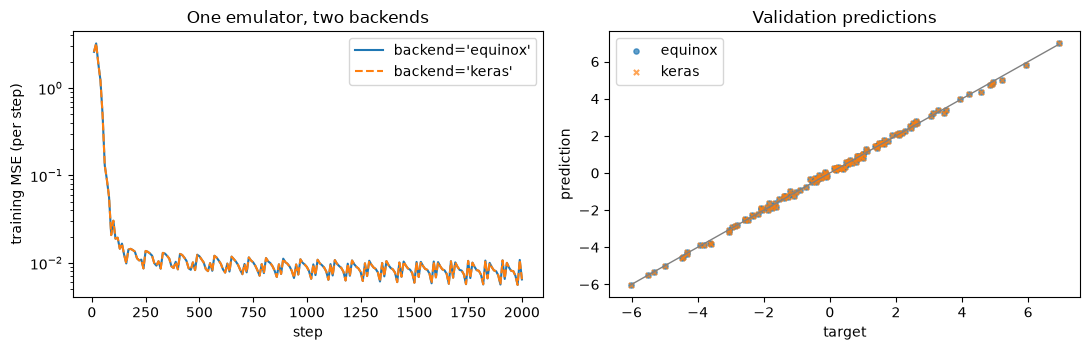

In [9]:
def losses(path: Path) -> tuple[np.ndarray, np.ndarray]:
    rows = [json.loads(line) for line in path.read_text().splitlines()]
    return np.array([r["step"] for r in rows]), np.array(
        [r["metrics"]["mse"] for r in rows]
    )


fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for backend, style in (("equinox", "-"), ("keras", "--")):
    steps, mse = losses(workdir / f"emulator-{backend}.jsonl")
    axes[0].plot(steps, mse, style, label=f"backend={backend!r}")
axes[0].set_yscale("log")
axes[0].set_xlabel("step")
axes[0].set_ylabel("training MSE (per step)")
axes[0].set_title("One emulator, two backends")
axes[0].legend()

for backend, marker in (("equinox", "o"), ("keras", "x")):
    predicted = np.asarray(jax.vmap(runs[backend])(x_val))
    axes[1].scatter(
        y_val[:, 0], predicted[:, 0], s=14, marker=marker, alpha=0.7, label=backend
    )
lims = [float(y_val.min()), float(y_val.max())]
axes[1].plot(lims, lims, color="grey", linewidth=1)
axes[1].set_xlabel("target")
axes[1].set_ylabel("prediction")
axes[1].set_title("Validation predictions")
axes[1].legend()
fig.tight_layout()
plt.show()

In [10]:
# Reproducibility readout — version metadata for the committed outputs.
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic(
        "watermark", "-v -m -p numpy,jax,keras,equinox,pipekit_train"
    )
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.19.1

numpy        : 2.4.4
jax          : 0.10.1
keras        : 3.14.1
equinox      : 0.13.8
pipekit_train: 0.3.1

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit

